In [1]:
import re

def split_into_chunks(text, max_words=100):
    # Split text into paragraphs
    paragraphs = re.split(r"\n+", text)
    chunks = []

    for para in paragraphs:
        para = para.strip()
        if not para:
            continue
        # Simple word tokenization using split
        words = para.split()

        # Break into chunks
        for i in range(0, len(words), max_words):
            chunk = " ".join(words[i:i+max_words])
            if len(chunk.split()) > 5:  # keep only meaningful chunks
                chunks.append(chunk)
    return chunks


In [2]:
import zipfile

# path to your zipped dataset
zip_path = "InauguralSpeeches.zip"

# extract contents
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall("speeches_data")

# check what’s inside
import os
os.listdir("speeches_data")


['InauguralSpeeches', '__MACOSX']

In [3]:
# president_years[(president, speech_num)] = year
president_years = {
    ("GeorgeWashington", "1"): 1789,
    ("GeorgeWashington", "2"): 1793,
    ("JohnAdams", "1"): 1797,
    ("ThomasJefferson", "1"): 1801,
    ("ThomasJefferson", "2"): 1805,
    ("JamesMadison", "1"): 1809,
    ("JamesMadison", "2"): 1813,
    ("JamesMonroe", "1"): 1817,
    ("JamesMonroe", "2"): 1821,
    ("JohnQuincyAdams", "1"): 1825,
    ("AndrewJackson", "1"): 1829,
    ("AndrewJackson", "2"): 1833,
    ("MartinVanBuren", "1"): 1837,
    ("WilliamHenryHarrison", "1"): 1841,
    ("JamesKPolk", "1"): 1845,
    ("ZacharyTaylor", "1"): 1849,
    ("FranklinPierce", "1"): 1853,
    ("JamesBuchanan", "1"): 1857,
    ("AbrahamLincoln", "1"): 1861,
    ("AbrahamLincoln", "2"): 1865,
    ("UlyssesSGrant", "1"): 1869,
    ("UlyssesSGrant", "2"): 1873,
    ("RutherfordBHays", "1"): 1877,
    ("JamesAGarfield", "1"): 1881,
    ("GroverCleveland", "1"): 1885,
    ("BenjaminHarrison", "1"): 1889,
    ("GroverCleveland", "2"): 1893,
    ("WilliamMcKinley", "1"): 1897,
    ("WilliamMcKinley", "2"): 1901,
    ("TheodoreRoosevelt", "1"): 1905,
    ("WilliamHowardTaft", "1"): 1909,
    ("WoodrowWilson", "1"): 1913,
    ("WoodrowWilson", "2"): 1917,
    ("WarrenGHarding", "1"): 1921,
    ("CalvinCoolidge", "1"): 1925,
    ("HerbertHoover", "1"): 1929,
    ("FranklinDRoosevelt", "1"): 1933,
    ("FranklinDRoosevelt", "2"): 1937,
    ("FranklinDRoosevelt", "3"): 1941,
    ("FranklinDRoosevelt", "4"): 1945,
    ("HarrySTruman", "1"): 1949,
    ("DwightDEisenhower", "1"): 1953,
    ("DwightDEisenhower", "2"): 1957,
    ("JohnFKennedy", "1"): 1961,
    ("LyndonBJohnson", "1"): 1965,
    ("RichardNixon", "1"): 1969,
    ("RichardNixon", "2"): 1973,
    ("JimmyCarter", "1"): 1977,
    ("RonaldReagan", "1"): 1981,
    ("RonaldReagan", "2"): 1985,
    ("GeorgeBush", "1"): 1989,
    ("BillClinton", "1"): 1993,
    ("BillClinton", "2"): 1997,
    ("GeorgeWBush", "1"): 2001,
    ("GeorgeWBush", "2"): 2005,
    ("BarackObama", "1"): 2009,
    ("BarackObama", "2"): 2013,
    ("DonaldTrump", "1"): 2017,
    ("JoeBiden", "1"): 2021,
    ("GroverCleveland-I", "1"): 1885,
    ("GroverCleveland-II", "2"): 1893,
    ("WilliamJClinton", "1"): 1993,
    ("WilliamJClinton", "2"): 1997,
    ("JamesGarfield", "1"): 1881,
    ("RutherfordBHayes", "1"): 1877,
    ("MartinvanBuren", "1"): 1837,
    ("DonaldJTrump", "1"): 2017,
}


In [4]:
import os
import pandas as pd
import re

speech_dir = "speeches_data/InauguralSpeeches"

data = []
for filename in os.listdir(speech_dir):
    if filename.endswith(".txt"):
        with open(os.path.join(speech_dir, filename), "r", encoding="utf-8") as f:
            text = f.read()

        base = filename.replace("inaug", "").replace(".txt", "")

        # Extract year if present
        match = re.search(r"\d{4}", base)
        if match:
            year = int(match.group())
            speech_num = base.split("-")[-1] if "-" in base else "1"
            president = None  # unknown from filename
        else:
            # If no year, assume format: PresidentName-SpeechNum
            if "-" in base:
                president, speech_num = base.rsplit("-", 1)
            else:
                president, speech_num = base, "1"

            president = president.strip()
            year = president_years.get((president, speech_num), None)

        data.append({
            "filename": filename,
            "president": president,
            "speech_num": speech_num,
            "year": year,
            "speech": text
        })

df = pd.DataFrame(data)
print(df.head())

                        filename           president speech_num  year  \
0  inaugGroverCleveland-II-2.txt  GroverCleveland-II          2  1893   
1       inaugJamesBuchanan-1.txt       JamesBuchanan          1  1857   
2         inaugBarackObama-2.txt         BarackObama          2  2013   
3     inaugWilliamMcKinley-2.txt     WilliamMcKinley          2  1901   
4     inaugWilliamJClinton-2.txt     WilliamJClinton          2  1997   

                                              speech  
0   My Fellow-Citizens:In obedience of the mandat...  
1   Fellow-Citizens:I appear before you this day ...  
2   Thank you. Thank you so much. Vice President ...  
3   My Fellow-Citizens:When we assembled here on ...  
4   My fellow citizens, at this last Presidential...  


In [5]:
#nan_year_rows = df[df["year"].isna()]
#print(nan_year_rows)

In [6]:
chunk_data = []
for _, row in df.iterrows():
    chunks = split_into_chunks(row["speech"], max_words=100)
    for i, chunk in enumerate(chunks):
        chunk_data.append({
            "year": row["year"],
            "president": row["president"],
            "speech_num": row["speech_num"],
            "chunk_id": f"{row['filename']}_chunk{i}",
            "speech_chunk": chunk.lower()
        })

df_chunks = pd.DataFrame(chunk_data)
print(df_chunks.head())
print("Total chunks:", len(df_chunks))


   year           president speech_num                              chunk_id  \
0  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk0   
1  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk1   
2  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk2   
3  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk3   
4  1893  GroverCleveland-II          2  inaugGroverCleveland-II-2.txt_chunk4   

                                        speech_chunk  
0  my fellow-citizens:in obedience of the mandate...  
1  refer to the existence of certain conditions a...  
2  of life and rejoices in the hardihood of const...  
3  at once arouse to activity the most enlightene...  
4  from intolerance or passion, and our judgments...  
Total chunks: 1398


In [7]:
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN

# --- 1. Custom vectorizer ---
vectorizer_model = CountVectorizer(stop_words="english", min_df=2)

# --- 2. UMAP and HDBSCAN for dimensionality reduction & clustering ---
umap_model = UMAP(n_neighbors=5, n_components=5, min_dist=0.0, metric='cosine')
hdbscan_model = HDBSCAN(min_cluster_size=5, min_samples=2, metric='euclidean', cluster_selection_method='eom')

# --- 3. Initialize BERTopic ---
topic_model = BERTopic(
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    verbose=True
)

# --- 4. Fit BERTopic on the speech chunks ---
docs = df_chunks["speech_chunk"].tolist()  # use chunks, not full speeches
topics, probs = topic_model.fit_transform(docs)

2025-10-03 11:52:21,464 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/44 [00:00<?, ?it/s]

2025-10-03 11:52:24,872 - BERTopic - Embedding - Completed ✓
2025-10-03 11:52:24,872 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2025-10-03 11:52:28,211 - BERTopic - Dimensionality - Completed ✓
2025-10-03 11:52:28,212 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-10-03 11:52:28,226 - BERTopic - Cluster - Completed ✓
2025-10-03 11:52:28,227 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-10-03 11:52:28,289 - BERTopic - Representation - Completed ✓


In [8]:
topic_model.visualize_topics()

In [9]:
topic_model.visualize_barchart()

In [10]:
topic_model.visualize_hierarchy()

In [11]:
# Get topic info from BERTopic
topic_info = topic_model.get_topic_info()
total_chunks = len(df_chunks)  # number of chunks

table = []

for _, row in topic_info.iterrows():
    topic_id = row["Topic"]
    count = row["Count"]
    perc = (count / total_chunks) * 100

    if topic_id == -1:
        # Label outliers explicitly
        topic_name = "Outliers"
        topic_def = "Not related to other topics"
    else:
        top_words = topic_model.get_topic(topic_id)
        if top_words:
            topic_name = ", ".join([w for w, _ in top_words[:3]])
            topic_def = f"Mainly about {topic_name}"
        else:
            topic_name = "Unknown"
            topic_def = "No representative words"

    table.append([topic_id, topic_name, topic_def, f"{perc:.1f}%"])

# Create a summary DataFrame
df_topics = pd.DataFrame(
    table,
    columns=["Topic", "Name", "Topic Definition", "Percentage of Chunks"]
)

print(df_topics)


     Topic                             Name  \
0       -1                         Outliers   
1        0           liberty, freedom, know   
2        1     duties, performance, station   
3        2        faith, believe, americans   
4        3             helped, life, vision   
..     ...                              ...   
120    119  citizen, possessed, unalienable   
121    120     slavery, minority, territory   
122    121        revenue, tariff, taxation   
123    122     officers, trusted, intrusted   
124    123           tax, industry, wealthy   

                                 Topic Definition Percentage of Chunks  
0                     Not related to other topics                18.5%  
1             Mainly about liberty, freedom, know                 2.3%  
2       Mainly about duties, performance, station                 1.7%  
3          Mainly about faith, believe, americans                 1.6%  
4               Mainly about helped, life, vision                 1.4%

In [ ]:
from openai import OpenAI
key = "Your_API_Key"
client = OpenAI(api_key=key)

def summarize_economy(text, year, president):
    prompt = f"""
    You are analyzing U.S. presidential inaugural speeches.
    Extract and summarize how the topic of *economy* is discussed in this speech
    ({president}, {year}). Focus on economic themes like trade, taxation, growth, jobs,
    industry, commerce, and fiscal policy. Provide 2–3 sentences.
    """
    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": prompt + "\n\n" + text[:1500]}] # send first ~1500 chars
    )
    return response.choices[0].message.content



In [13]:
economy_keywords = [
    "economy", "economic", "commerce", "industry", "trade",
    "business", "jobs", "growth", "prosperity", "tax", "labor"
]

df["economy_mentions"] = df["speech"].str.lower().apply(
    lambda x: sum(word in x for word in economy_keywords)
)



# Group speeches into 20-year bins
df["period"] = (df["year"] // 20) * 20

trend = df.groupby("period")["economy_mentions"].mean().reset_index()



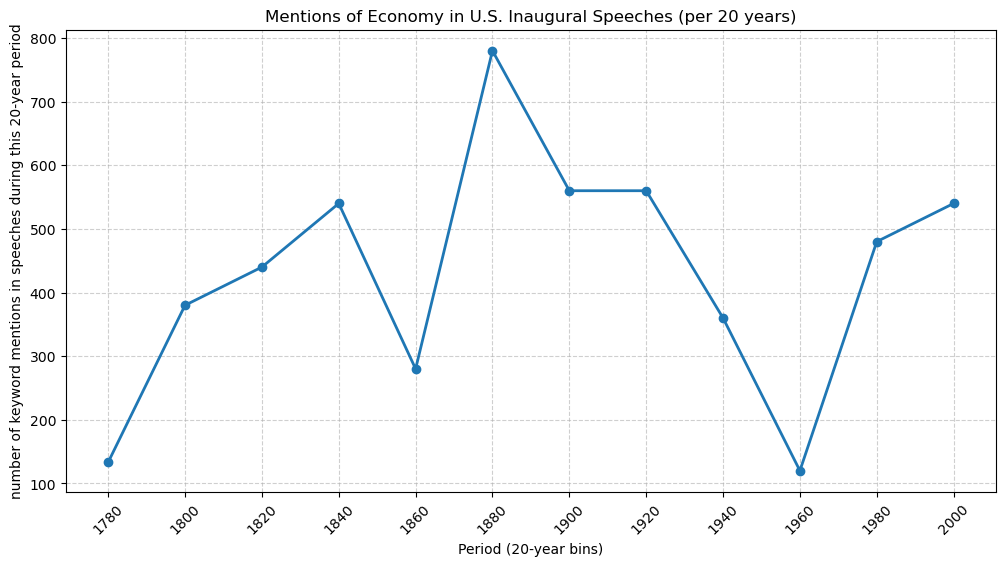

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(trend["period"], trend["economy_mentions"]*100, marker="o", linewidth=2)
plt.title("Mentions of Economy in U.S. Inaugural Speeches (per 20 years)")
plt.xlabel("Period (20-year bins)")
plt.ylabel("number of keyword mentions in speeches during this 20-year period")
plt.xticks(trend["period"], rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


In [15]:
summaries = []
for period, group in df.groupby("period"):
    combined_text = " ".join(group["speech"].tolist())
    summary = summarize_economy(combined_text, f"{period}s", "Multiple Presidents")
    summaries.append({"period": period, "summary": summary})

df_summaries = pd.DataFrame(summaries)

pd.set_option("display.max_colwidth", None)
df_summaries


,period,summary
0,1780,"In the early presidential inaugural speeches, the topic of the economy is often framed within the broader context of independence and governance. The emphasis is on creating a stable government that would facilitate commerce and trade, fostering economic growth while maintaining unity among states. Concerns are expressed over potential internal conflicts that could arise from differing economic interests, underscoring the need for effective fiscal policies to support industry and job creation as the nation seeks to establish its identity and economic foundations post-independence."
1,1800,"In this inaugural speech from the 1800s, the topic of the economy is addressed through reflections on national prosperity and the contrast of past and present economic conditions. The President highlights the nation's recent peak in prosperity, attributing this success to the effectiveness of republican governance and peaceful international relations, which have facilitated growth in agriculture, commerce, and manufacturing. The acknowledgment of challenges arising during this time underscores the delicate balance between maintaining economic momentum and addressing impending difficulties."
2,1820,"In this inaugural speech, the topic of the economy is subtly woven into the broader discussion of governance and foreign policy. The speaker emphasizes the importance of maintaining justice and equitable relations with other nations, which indirectly supports trade and commerce by promoting a peaceful international environment that is conducive to economic growth. Additionally, the reference to governmental efforts aimed at preserving liberty and promoting happiness suggests a commitment to policies that would favor job creation and fiscal responsibility, although specific economic measures such as taxation or industry are not explicitly detailed."
3,1840,"In this inaugural speech from a U.S. president in the 1840s, the topic of the economy is approached indirectly, with an emphasis on unity and governance rather than specific economic policies. While the speech does not explicitly address themes such as trade, taxation, or jobs, it highlights the importance of preserving harmony and the institutions that contribute to national prosperity. The president seeks to ensure the support of the citizenry in sustaining measures that perpetuate the nation's political blessings, implying an understanding that a stable government is essential for a thriving economy."
4,1860,"In the inaugural speech, the topic of the economy is addressed through reflections on recovery and restoration following a significant internal conflict. The speaker emphasizes the importance of public credit, commerce, and the arts of peace, suggesting that a stable economy is critical for national harmony and progress. The mention of maintaining a comparatively smaller military force indicates a focus on redirecting resources towards industrial and economic growth rather than military expansion, reinforcing a commitment to fiscal responsibility and rebuilding the nation's economic foundations."
5,1880,"In this inaugural speech, the President discusses the U.S. economy by acknowledging the significant growth and expansion of the country, highlighting the industrious nature and enterprise of its citizens. However, he also warns of underlying dangers that may threaten the integrity of government and the economy, likening these threats to a hidden disease that could lead to collapse. This reflects a concern for ensuring robust fiscal policies and vigilant oversight to maintain economic vitality and stability."
6,1900,"In this inaugural speech, the President reflects on the economic recovery of the United States from a period of financial distress, emphasizing improvements in currency stability and fiscal health, including a surplus that allows for reduced taxation. The speech highlights the resurgence of manufacturing, mining, and agriculture, noting that labor is f